## Step 1: Find each paper's year

In [2]:
import pandas as pd

papers = pd.read_csv("topic_assignments_draft.csv")
print("Papers loaded:", len(papers))

# Extract publication year from the source field (e.g., "Journal, 2024-09, Vol.24")
papers["year"] = (
    papers["Is Part Of"].astype(str)
    .str.extract(r",\s*((?:19|20)\d\d)")[0]
    .astype(float)
)
print("Missing years:", papers["year"].isna().sum())
print("Range:", int(papers["year"].min()), "-", int(papers["year"].max()))

# Group into periods; early years are pooled because they contain few papers
papers["period"] = pd.cut(
    papers["year"],
    bins=[2000, 2012, 2018, 2022, 2026],
    labels=["2001-12", "2013-18", "2019-22", "2023-26"],
)
print(papers["period"].value_counts().sort_index())

papers.to_csv("step1_papers_with_year.csv", index=False, encoding="utf-8-sig")

Papers loaded: 3905
Missing years: 0
Range: 2001 - 2026
period
2001-12     222
2013-18     336
2019-22     900
2023-26    2447
Name: count, dtype: int64


## Step 2: Mark what each abstract talks about

In [3]:
import pandas as pd

papers = pd.read_csv("step1_papers_with_year.csv")
text = papers["analysis_text"].fillna("").str.lower()

# Dictionary-based indicators of outcome and measurement language
indicators = {
    "objective_measure": (
        r"\bosats\b|completion time|task time|\berrors?\b|path length|"
        r"economy of motion|accuracy|construct validity|global rating|"
        r"\bgrs\b|blinded|checklist score|procedure time"
    ),
    "self_report": (
        r"satisf\w*|percep\w*|perceived|questionnaire|survey|likert|"
        r"self[- ]report\w*|attitude\w*|acceptab\w*|opinion"
    ),
    "engagement_confidence": r"\bengag\w*|\bmotivat\w*|self[- ]efficacy|\bconfiden\w*",
    "knowledge": r"\bknowledge\b|test scores?|post[- ]?test|exam\w*",
    "skill_performance": r"\bskills?\b|\bperform\w*|competenc\w*|proficien\w*",
    "transfer": r"\btransfer\w*|operating room|real patients?|in vivo|on patients",
    "promissory": (
        r"\bpotential\b|promis\w*|\bfuture\b|emerging|transform\w*|"
        r"revolution\w*|novel|innovative|opportunit\w*"
    ),
}

for name, pattern in indicators.items():
    papers[name] = text.str.contains(pattern, regex=True)

print((papers[list(indicators)].mean() * 100).round(1))

papers.to_csv("step2_papers_with_flags.csv", index=False, encoding="utf-8-sig")

objective_measure        19.5
self_report              45.3
engagement_confidence    29.6
knowledge                42.5
skill_performance        65.8
transfer                 11.2
promissory               59.6
dtype: float64


## Step 3: Compare the ten topics

In [4]:
import pandas as pd

papers = pd.read_csv("step2_papers_with_flags.csv")

topic_labels = {
    1: "Clinical sim design", 2: "Task training & feedback",
    3: "Surgical education", 4: "3D anatomy", 5: "Dental VR & haptics",
    6: "Evidence syntheses", 7: "Metaverse", 8: "Nursing simulation",
    9: "AI integration", 10: "Instruction & outcomes",
}
papers["topic_label"] = papers["topic_number"].map(topic_labels)

indicators = ["objective_measure", "self_report", "engagement_confidence",
              "knowledge", "skill_performance", "transfer", "promissory"]

# Share of abstracts in each topic that contain each indicator (%)
by_topic = (papers.groupby("topic_label")[indicators].mean() * 100).round(1)
by_topic["papers"] = papers.groupby("topic_label").size()
by_topic["median_year"] = papers.groupby("topic_label")["year"].median()
by_topic = by_topic.sort_values("objective_measure", ascending=False)

print(by_topic[["papers", "median_year", "objective_measure",
                "engagement_confidence", "self_report", "transfer"]].to_string())

by_topic.to_csv("step3_topic_comparison.csv", encoding="utf-8-sig")

                          papers  median_year  objective_measure  engagement_confidence  self_report  transfer
topic_label                                                                                                   
Task training & feedback     622       2020.0               46.3                   13.7         35.7      23.2
Surgical education           430       2023.0               25.8                   12.8         28.8      22.8
AI integration               190       2025.0               24.7                   32.6         25.3       7.4
3D anatomy                   415       2024.0               20.7                   20.2         39.0       8.7
Dental VR & haptics          221       2024.0               17.2                   27.1         60.6      10.4
Evidence syntheses           456       2024.0               11.8                   34.2         32.7       8.3
Clinical sim design          339       2023.0               11.5                   33.0         43.1       5.6
I

## Step 4: Compare the four time periods

In [5]:
import pandas as pd

papers = pd.read_csv("step2_papers_with_flags.csv")
period_order = ["2001-12", "2013-18", "2019-22", "2023-26"]

indicators = ["objective_measure", "self_report", "engagement_confidence",
              "knowledge", "skill_performance", "transfer", "promissory"]

# (a) Share of abstracts in each period that contain each indicator (%)
by_period = (papers.groupby("period")[indicators].mean() * 100).round(1)
by_period = by_period.reindex(period_order)
by_period["papers"] = papers.groupby("period").size().reindex(period_order)
print(by_period[["papers", "objective_measure", "self_report",
                 "engagement_confidence", "transfer", "promissory"]].to_string())
by_period.to_csv("step4_period_comparison.csv", encoding="utf-8-sig")

# (b) Composition of each period by research stream (rows sum to 100%)
streams = {
    2: "Procedural task training", 3: "Procedural task training", 5: "Procedural task training",
    1: "Learning-experience studies", 4: "Learning-experience studies",
    8: "Learning-experience studies", 10: "Learning-experience studies",
    6: "Evidence syntheses", 7: "Prospective / visionary", 9: "Prospective / visionary",
}
papers["stream"] = papers["topic_number"].map(streams)

mix = (pd.crosstab(papers["period"], papers["stream"], normalize="index") * 100).round(1)
mix = mix.reindex(period_order)
print()
print(mix.to_string())
mix.to_csv("step4_topic_mix_by_period.csv", encoding="utf-8-sig")

         papers  objective_measure  self_report  engagement_confidence  transfer  promissory
period                                                                                      
2001-12     222               32.4         22.5                    6.3      18.9        33.8
2013-18     336               25.3         34.2                   14.6      20.2        41.7
2019-22     900               17.1         43.3                   20.6      14.0        54.0
2023-26    2447               18.4         49.6                   37.1       8.3        66.4

stream   Evidence syntheses  Learning-experience studies  Procedural task training  Prospective / visionary
period                                                                                                     
2001-12                 0.0                         26.6                      73.4                      0.0
2013-18                 5.1                         37.5                      56.2                      1.2
2019-22  

## Step 5: Is the change real inside each topic?

In [6]:
import pandas as pd

papers = pd.read_csv("step2_papers_with_flags.csv")

topic_labels = {
    1: "Clinical sim design", 2: "Task training & feedback",
    3: "Surgical education", 4: "3D anatomy", 5: "Dental VR & haptics",
    6: "Evidence syntheses", 7: "Metaverse", 8: "Nursing simulation",
    9: "AI integration", 10: "Instruction & outcomes",
}
papers["topic_label"] = papers["topic_number"].map(topic_labels)

# Compare early (<=2019) and recent (>=2023) papers within each topic
papers["era"] = pd.cut(papers["year"], bins=[2000, 2019, 2022, 2026],
                       labels=["early", "middle", "recent"])
compare = papers[papers["era"].isin(["early", "recent"])]

rows = []
for indicator in ["engagement_confidence", "self_report", "objective_measure", "transfer"]:
    pct = compare.groupby(["topic_label", "era"], observed=True)[indicator].mean().unstack() * 100
    n_early = compare[compare["era"] == "early"].groupby("topic_label").size()
    for topic in pct.index:
        rows.append({
            "indicator": indicator,
            "topic": topic,
            "n_early": int(n_early.get(topic, 0)),
            "early_%": round(pct.loc[topic, "early"], 1),
            "recent_%": round(pct.loc[topic, "recent"], 1),
        })

result = pd.DataFrame(rows)
result["change"] = (result["recent_%"] - result["early_%"]).round(1)
result["enough_early_papers"] = result["n_early"] >= 10   # small early groups are unstable

for indicator, part in result.groupby("indicator", sort=False):
    usable = part[part["enough_early_papers"]]
    print(f"\n{indicator}: up in {(usable['change'] > 0).sum()} of {len(usable)} topics, "
          f"down in {(usable['change'] < 0).sum()}")
    print(part.drop(columns="indicator").to_string(index=False))

result.to_csv("step5_within_topic_early_vs_recent.csv", index=False, encoding="utf-8-sig")


engagement_confidence: up in 8 of 8 topics, down in 0
                   topic  n_early  early_%  recent_%  change  enough_early_papers
              3D anatomy       71     15.5      26.6    11.1                 True
          AI integration        1      0.0      33.3    33.3                False
     Clinical sim design       70     24.3      39.9    15.6                 True
     Dental VR & haptics       33      9.1      33.6    24.5                 True
      Evidence syntheses       29     10.3      40.5    30.2                 True
  Instruction & outcomes       64     20.3      48.9    28.6                 True
               Metaverse        8     25.0      38.6    13.6                False
      Nursing simulation       32     18.8      50.9    32.1                 True
      Surgical education       81      3.7      17.7    14.0                 True
Task training & feedback      286      8.0      22.8    14.8                 True

self_report: up in 7 of 8 topics, down in 

## Step 6 (optional): Regression version of Step 5

In [7]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

papers = pd.read_csv("step2_papers_with_flags.csv")

# Time expressed in 5-year units centred on 2020, so results read "per 5 years"
papers["five_years"] = (papers["year"] - 2020) / 5

rows = []
for indicator in ["engagement_confidence", "self_report", "objective_measure",
                  "transfer", "knowledge", "skill_performance", "promissory"]:
    papers["y"] = papers[indicator].astype(int)
    # Logistic regression with topic fixed effects: time trend within topics
    model = smf.logit("y ~ five_years + C(topic_number)", data=papers).fit(disp=0)
    low, high = np.exp(model.conf_int().loc["five_years"])
    rows.append({
        "indicator": indicator,
        "odds_ratio_per_5yr": round(np.exp(model.params["five_years"]), 2),
        "ci_95": f"{low:.2f}-{high:.2f}",
        "p_value": f"{model.pvalues['five_years']:.1g}",
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv("step6_regression_results.csv", index=False, encoding="utf-8-sig")

            indicator  odds_ratio_per_5yr     ci_95 p_value
engagement_confidence                2.11 1.84-2.41   1e-27
          self_report                1.46 1.34-1.60   8e-17
    objective_measure                1.13 1.03-1.24    0.01
             transfer                0.84 0.76-0.93  0.0006
            knowledge                1.14 1.04-1.24   0.004
    skill_performance                1.11 1.01-1.22    0.02
           promissory                1.41 1.30-1.53   4e-16


## Figure 1: Corpus flow diagram

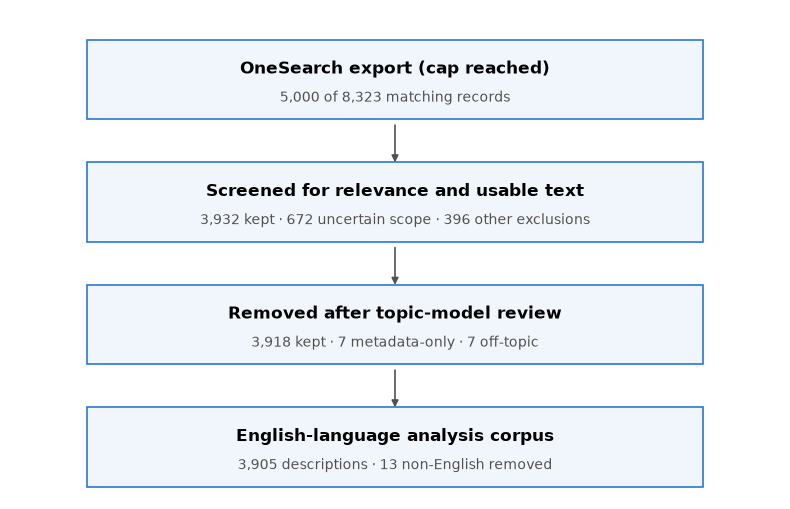

In [8]:
import matplotlib.pyplot as plt

# Record counts at each screening stage
stages = [
    ("OneSearch export (cap reached)", "5,000 of 8,323 matching records"),
    ("Screened for relevance and usable text",
     "3,932 kept · 672 uncertain scope · 396 other exclusions"),
    ("Removed after topic-model review", "3,918 kept · 7 metadata-only · 7 off-topic"),
    ("English-language analysis corpus", "3,905 descriptions · 13 non-English removed"),
]

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.set_xlim(0, 10)
ax.set_ylim(0, len(stages) * 2)
ax.axis("off")

for i, (title, detail) in enumerate(stages):
    y = len(stages) * 2 - 1.2 - i * 2
    ax.add_patch(plt.Rectangle((1, y - 0.6), 8, 1.3,
                               facecolor="#f1f6fd", edgecolor="#2a78d6", linewidth=1.2))
    ax.text(5, y + 0.22, title, ha="center", va="center", fontsize=12, weight="bold")
    ax.text(5, y - 0.25, detail, ha="center", va="center", fontsize=10, color="#52514e")
    if i < len(stages) - 1:
        ax.annotate("", xy=(5, y - 1.35), xytext=(5, y - 0.65),
                    arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=1.2))

fig.tight_layout()
fig.savefig("fig1_corpus_flow.png", dpi=220, bbox_inches="tight")
plt.show()

## Figure 2: Research mix over time

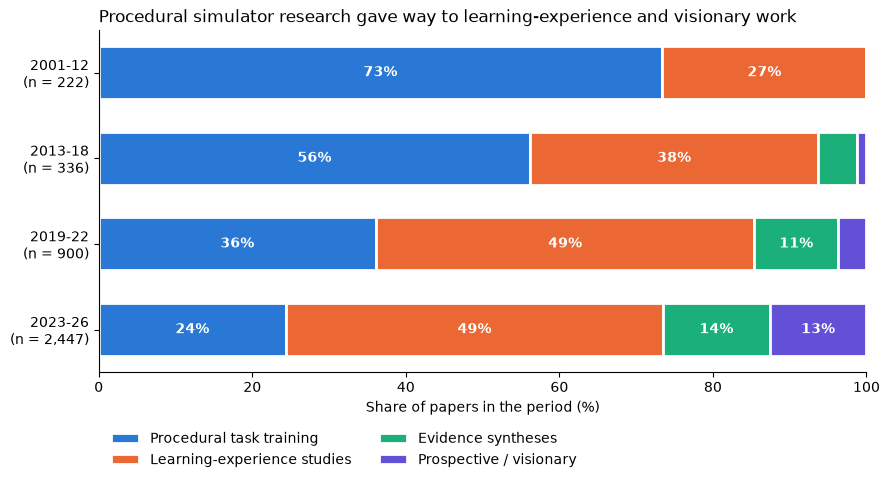

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mix = pd.read_csv("step4_topic_mix_by_period.csv", index_col="period")
counts = pd.read_csv("step4_period_comparison.csv", index_col="period")["papers"]

stream_order = ["Procedural task training", "Learning-experience studies",
                "Evidence syntheses", "Prospective / visionary"]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]

fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(mix))
for stream, color in zip(stream_order, colors):
    values = mix[stream].values
    ax.barh(range(len(mix)), values, left=left, color=color, height=0.62,
            edgecolor="white", linewidth=2, label=stream)
    for row, v in enumerate(values):
        if v >= 7:   # label only segments wide enough to hold text
            ax.text(left[row] + v / 2, row, f"{v:.0f}%", ha="center", va="center",
                    color="white", fontsize=10, weight="bold")
    left += values

ax.set_yticks(range(len(mix)))
ax.set_yticklabels([f"{p}\n(n = {counts[p]:,})" for p in mix.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of papers in the period (%)")
ax.set_title("Procedural simulator research gave way to learning-experience and visionary work",
             loc="left", fontsize=12)
ax.legend(ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.14), fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("fig2_stream_shift.png", dpi=220, bbox_inches="tight")
plt.show()

## Figure 3: Two clusters (bubble chart)

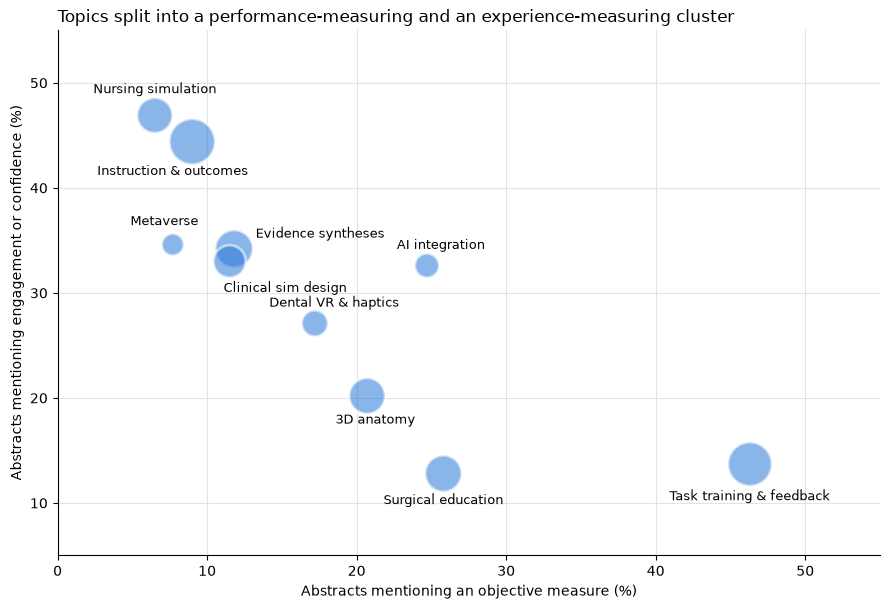

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

by_topic = pd.read_csv("step3_topic_comparison.csv", index_col="topic_label")

fig, ax = plt.subplots(figsize=(9, 6.2))
ax.scatter(by_topic["objective_measure"], by_topic["engagement_confidence"],
           s=by_topic["papers"] * 1.6, color="#2a78d6", alpha=0.55,
           edgecolor="white", linewidth=2)

# Label offsets (in points) to keep labels from overlapping
offsets = {"Task training & feedback": (0, -26), "Surgical education": (0, -22),
           "AI integration": (10, 12), "Evidence syntheses": (62, 8),
           "Metaverse": (-6, 14), "Nursing simulation": (0, 16),
           "Instruction & outcomes": (-14, -24), "Clinical sim design": (40, -22),
           "Dental VR & haptics": (14, 12), "3D anatomy": (6, -20)}
for label, row in by_topic.iterrows():
    ax.annotate(label, (row["objective_measure"], row["engagement_confidence"]),
                xytext=offsets.get(label, (0, 12)), textcoords="offset points",
                ha="center", fontsize=9.5)

ax.set_xlabel("Abstracts mentioning an objective measure (%)")
ax.set_ylabel("Abstracts mentioning engagement or confidence (%)")
ax.set_xlim(0, 55)
ax.set_ylim(5, 55)
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Topics split into a performance-measuring and an experience-measuring cluster",
             loc="left", fontsize=12)

fig.tight_layout()
fig.savefig("fig3_evidence_regimes.png", dpi=220, bbox_inches="tight")
plt.show()

## Figure 4: What gets measured over time

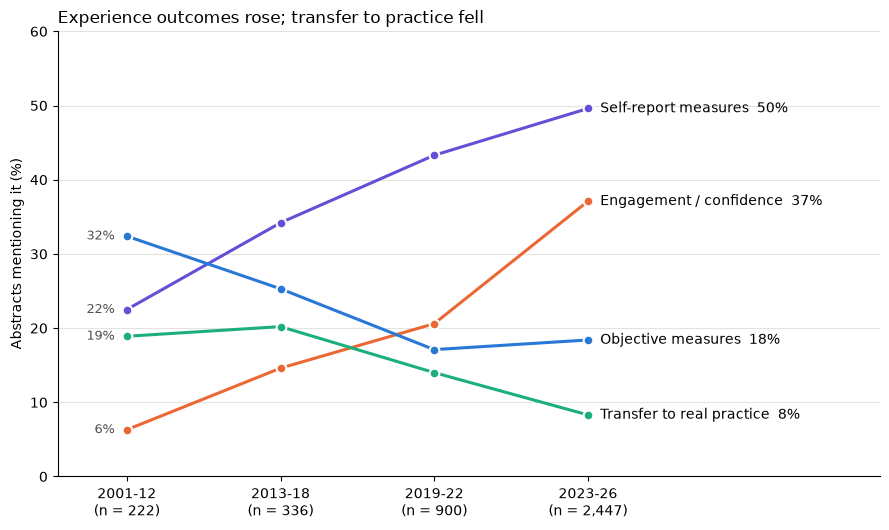

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

by_period = pd.read_csv("step4_period_comparison.csv", index_col="period")

lines = [("engagement_confidence", "Engagement / confidence", "#eb6834"),
         ("self_report", "Self-report measures", "#6250d6"),
         ("objective_measure", "Objective measures", "#2a78d6"),
         ("transfer", "Transfer to real practice", "#1baf7a")]
x = np.arange(len(by_period))

fig, ax = plt.subplots(figsize=(9, 5.4))
for column, label, color in lines:
    y = by_period[column].values
    ax.plot(x, y, color=color, linewidth=2.2, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.5)
    ax.text(x[-1] + 0.08, y[-1], f"{label}  {y[-1]:.0f}%", va="center", fontsize=10)
    ax.text(x[0] - 0.08, y[0], f"{y[0]:.0f}%", va="center", ha="right",
            fontsize=9.5, color="#52514e")

ax.set_xticks(x)
ax.set_xticklabels([f"{p}\n(n = {n:,})" for p, n in zip(by_period.index, by_period["papers"])])
ax.set_xlim(-0.45, len(x) + 0.9)
ax.set_ylim(0, 60)
ax.set_ylabel("Abstracts mentioning it (%)")
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Experience outcomes rose; transfer to practice fell", loc="left", fontsize=12)

fig.tight_layout()
fig.savefig("fig4_outcome_drift.png", dpi=220, bbox_inches="tight")
plt.show()

## Figure 5: Change inside each topic

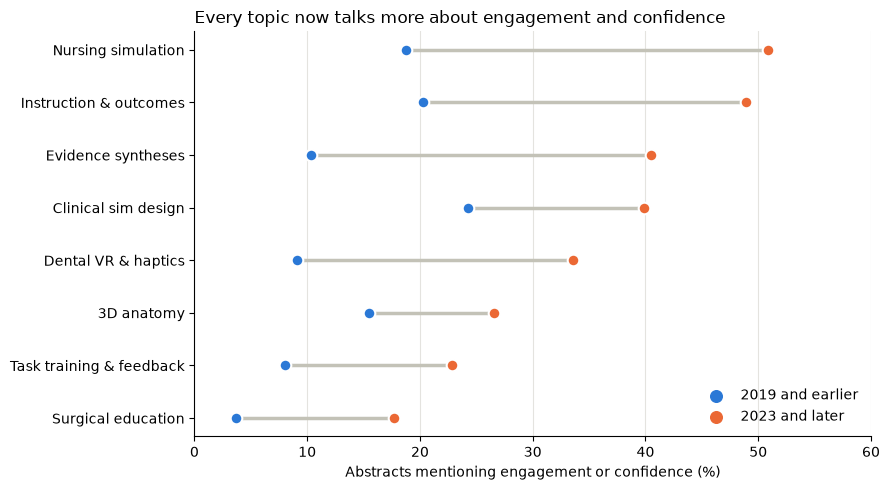

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

result = pd.read_csv("step5_within_topic_early_vs_recent.csv")

# Engagement/confidence only; exclude topics with fewer than 10 early papers
data = result[(result["indicator"] == "engagement_confidence") & result["enough_early_papers"]]
data = data.sort_values("recent_%").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5))
for i, row in data.iterrows():
    ax.plot([row["early_%"], row["recent_%"]], [i, i], color="#c3c2b7", linewidth=2.5, zorder=1)
    ax.scatter(row["early_%"], i, s=70, color="#2a78d6", zorder=2, edgecolor="white", linewidth=1.5)
    ax.scatter(row["recent_%"], i, s=70, color="#eb6834", zorder=2, edgecolor="white", linewidth=1.5)

ax.set_yticks(range(len(data)))
ax.set_yticklabels(data["topic"])
ax.set_xlabel("Abstracts mentioning engagement or confidence (%)")
ax.set_xlim(0, 60)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.scatter([], [], color="#2a78d6", s=70, label="2019 and earlier")
ax.scatter([], [], color="#eb6834", s=70, label="2023 and later")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Every topic now talks more about engagement and confidence", loc="left", fontsize=12)

fig.tight_layout()
fig.savefig("fig5_within_topic_drift.png", dpi=220, bbox_inches="tight")
plt.show()

## Figure 6: Theory diagram

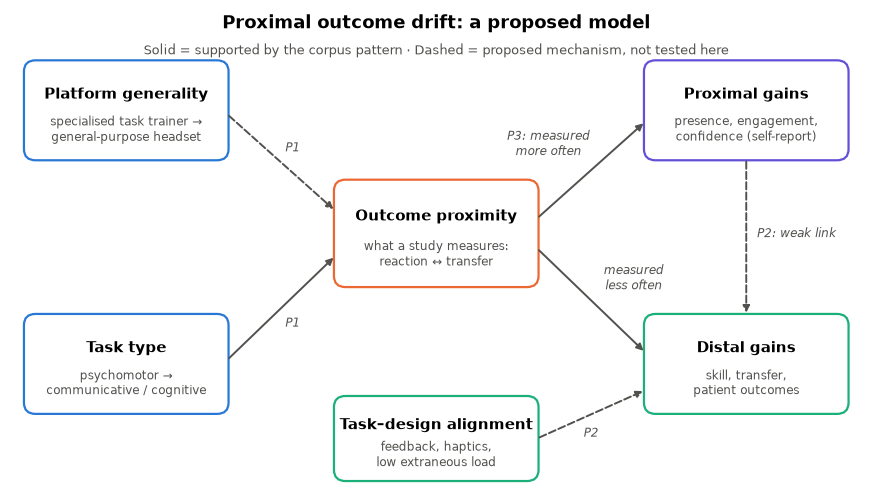

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, title, subtitle, edge):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                facecolor="white", edgecolor=edge, linewidth=1.6))
    ax.text(x + w / 2, y + h * 0.66, title, ha="center", va="center", fontsize=10.5, weight="bold")
    ax.text(x + w / 2, y + h * 0.3, subtitle, ha="center", va="center", fontsize=8.8, color="#52514e")

def arrow(ax, start, end, dashed=False, text=None, tx=0, ty=0):
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(
        arrowstyle="-|>", color="#52514e", lw=1.4,
        linestyle="--" if dashed else "-", shrinkA=2, shrinkB=2))
    if text:
        ax.text((start[0] + end[0]) / 2 + tx, (start[1] + end[1]) / 2 + ty, text,
                fontsize=8.6, color="#52514e", ha="center", style="italic")

fig, ax = plt.subplots(figsize=(11, 6.2))
ax.set_xlim(0, 11)
ax.set_ylim(0, 6.4)
ax.axis("off")

# Constructs
box(ax, 0.2, 4.4, 2.6, 1.3, "Platform generality", "specialised task trainer →\ngeneral-purpose headset", "#2a78d6")
box(ax, 0.2, 1.0, 2.6, 1.3, "Task type", "psychomotor →\ncommunicative / cognitive", "#2a78d6")
box(ax, 4.2, 2.7, 2.6, 1.4, "Outcome proximity", "what a study measures:\nreaction ↔ transfer", "#eb6834")
box(ax, 8.2, 4.4, 2.6, 1.3, "Proximal gains", "presence, engagement,\nconfidence (self-report)", "#6250d6")
box(ax, 8.2, 1.0, 2.6, 1.3, "Distal gains", "skill, transfer,\npatient outcomes", "#1baf7a")
box(ax, 4.2, 0.1, 2.6, 1.1, "Task–design alignment", "feedback, haptics,\nlow extraneous load", "#1baf7a")

# Propositions (solid = observed in corpus; dashed = proposed, untested)
arrow(ax, (2.8, 5.0), (4.2, 3.7), dashed=True, text="P1", tx=0.15, ty=0.15)
arrow(ax, (2.8, 1.7), (4.2, 3.1), text="P1", tx=0.15, ty=-0.25)
arrow(ax, (6.8, 3.6), (8.2, 4.9), text="P3: measured\nmore often", tx=-0.55, ty=0.2)
arrow(ax, (6.8, 3.2), (8.2, 1.8), text="measured\nless often", tx=0.55, ty=0.15)
arrow(ax, (9.5, 4.4), (9.5, 2.3), dashed=True, text="P2: weak link", tx=0.65, ty=0)
arrow(ax, (6.8, 0.65), (8.2, 1.3), dashed=True, text="P2", tx=0.0, ty=-0.3)

ax.text(5.5, 6.15, "Proximal outcome drift: a proposed model", ha="center", fontsize=13, weight="bold")
ax.text(5.5, 5.8, "Solid = supported by the corpus pattern · Dashed = proposed mechanism, not tested here",
        ha="center", fontsize=9, color="#52514e")

fig.savefig("fig6_theory_model.png", dpi=220, bbox_inches="tight")
plt.show()

## Step 8: Make the hand-check sheet

In [14]:
import pandas as pd

papers = pd.read_csv("step2_papers_with_flags.csv")
indicators = ["engagement_confidence", "self_report", "objective_measure", "transfer"]

# Random validation sample (fixed seed for reproducibility)
sample = papers.sample(60, random_state=2026)

# Coding sheet: abstracts with blank columns for manual codes
sheet = sample[["source_row", "Title", "analysis_text"]].copy()
for name in indicators:
    sheet["my_" + name] = ""
sheet.to_csv("step8_hand_check_sheet.csv", index=False, encoding="utf-8-sig")

# Automated codes stored separately so they do not influence manual coding
sample[["source_row"] + indicators].to_csv("step8_computer_answers.csv",
                                           index=False, encoding="utf-8-sig")
print("Coding sheet saved:", len(sheet), "abstracts")

Coding sheet saved: 60 abstracts


## Step 9: Score your hand check (run only after filling in the sheet)

In [15]:
import pandas as pd

manual = pd.read_excel("step8_hand_check_sheet.xlsx")
auto = pd.read_csv("step8_computer_answers.csv")
merged = manual.merge(auto, on="source_row")

rows = []
for name in ["engagement_confidence", "self_report", "objective_measure", "transfer"]:
    coded = pd.to_numeric(merged["my_" + name], errors="coerce").notna()
    human = merged.loc[coded, "my_" + name].astype(int)
    machine = merged.loc[coded, name].astype(bool).astype(int)
    rows.append({
        "indicator": name,
        "abstracts_coded": int(coded.sum()),
        "agreement": round((human == machine).mean(), 2),
        "dictionary_yes": int(machine.sum()),
        "manual_yes": int(human.sum()),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv("step9_validation_results.csv", index=False, encoding="utf-8-sig")

            indicator  abstracts_coded  agreement  dictionary_yes  manual_yes
engagement_confidence               60       0.77              18          16
          self_report               60       0.78              30          33
    objective_measure               60       0.78              15          18
             transfer               60       0.80               9           3


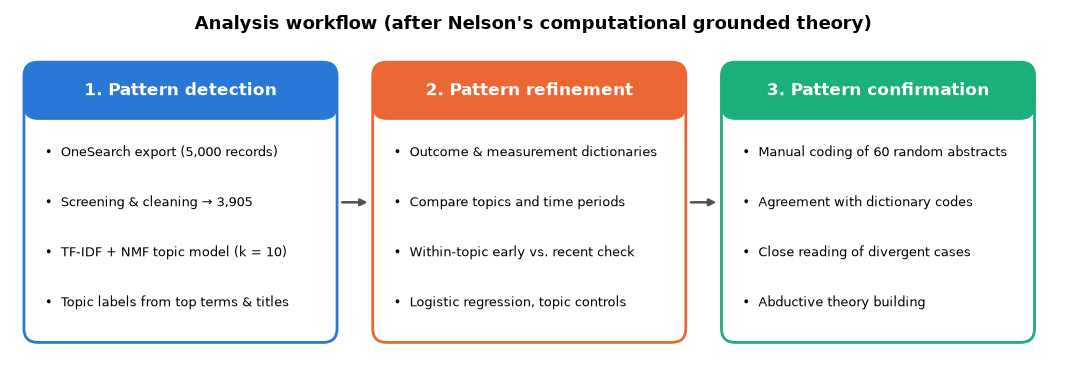

In [16]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Analysis workflow organized by the three stages of computational grounded theory
stages = [
    ("1. Pattern detection", "#2a78d6",
     ["OneSearch export (5,000 records)", "Screening & cleaning → 3,905",
      "TF-IDF + NMF topic model (k = 10)", "Topic labels from top terms & titles"]),
    ("2. Pattern refinement", "#eb6834",
     ["Outcome & measurement dictionaries", "Compare topics and time periods",
      "Within-topic early vs. recent check", "Logistic regression, topic controls"]),
    ("3. Pattern confirmation", "#1baf7a",
     ["Manual coding of 60 random abstracts", "Agreement with dictionary codes",
      "Close reading of divergent cases", "Abductive theory building"]),
]

fig, ax = plt.subplots(figsize=(13.5, 4.6))
ax.set_xlim(0, 13.5)
ax.set_ylim(0, 4.6)
ax.axis("off")

for i, (title, color, items) in enumerate(stages):
    x = 0.2 + i * 4.5
    ax.add_patch(FancyBboxPatch((x, 0.3), 4.0, 3.6, boxstyle="round,pad=0.02,rounding_size=0.18",
                                facecolor="white", edgecolor=color, linewidth=2))
    ax.add_patch(FancyBboxPatch((x, 3.2), 4.0, 0.7, boxstyle="round,pad=0.02,rounding_size=0.18",
                                facecolor=color, edgecolor=color))
    ax.text(x + 2.0, 3.55, title, ha="center", va="center", fontsize=12.5, weight="bold", color="white")
    for j, item in enumerate(items):
        ax.text(x + 0.25, 2.75 - j * 0.65, "•  " + item, ha="left", va="center", fontsize=9.3)
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + 4.45, 2.1), xytext=(x + 4.05, 2.1),
                    arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=1.8))

ax.text(6.75, 4.35, "Analysis workflow (after Nelson's computational grounded theory)",
        ha="center", fontsize=13, weight="bold")

fig.savefig("fig0_workflow.png", dpi=220, bbox_inches="tight")
plt.show()

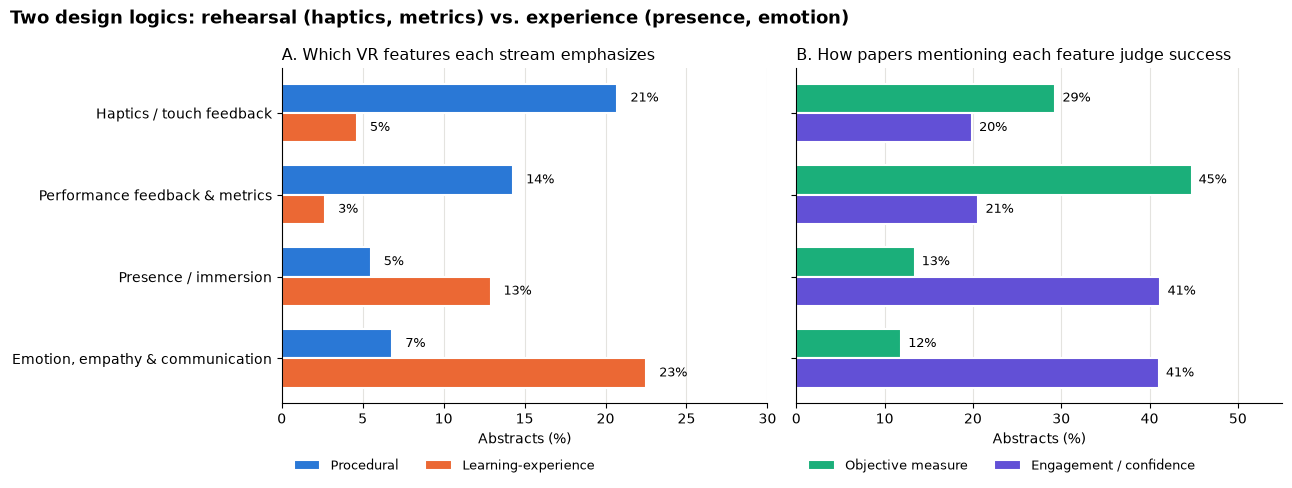

stream                            Learning-experience  Procedural
Haptics / touch feedback                          4.6        20.7
Performance feedback & metrics                    2.7        14.3
Presence / immersion                             12.9         5.5
Emotion, empathy & communication                 22.5         6.8
                                  Objective measure  Engagement / confidence
Haptics / touch feedback                       29.3                     19.9
Performance feedback & metrics                 44.8                     20.6
Presence / immersion                           13.4                     41.2
Emotion, empathy & communication               11.9                     41.1


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

papers = pd.read_csv("step2_papers_with_flags.csv")
text = papers["analysis_text"].fillna("").str.lower()

# Design features emphasized in abstracts (dictionary indicators)
features = {
    "Haptics / touch feedback": r"haptic|force feedback|tactile",
    "Performance feedback & metrics": r"real[- ]time feedback|automated feedback|performance feedback|metrics|objective feedback",
    "Presence / immersion": r"\bpresence\b|immersion|immersive experience|sense of being",
    "Emotion, empathy & communication": r"empath|emotion|anxiety|stress|social presence|communication",
}
for name, pattern in features.items():
    papers[name] = text.str.contains(pattern, regex=True)

streams = {2: "Procedural", 3: "Procedural", 5: "Procedural",
           1: "Learning-experience", 4: "Learning-experience",
           8: "Learning-experience", 10: "Learning-experience"}
papers["stream"] = papers["topic_number"].map(streams)

# Left panel: share of each stream's abstracts mentioning each feature
by_stream = (papers.groupby("stream")[list(features)].mean() * 100).T

# Right panel: how papers mentioning each feature evaluate outcomes
evaluation = pd.DataFrame({
    "Objective measure": [papers.loc[papers[f], "objective_measure"].mean() * 100 for f in features],
    "Engagement / confidence": [papers.loc[papers[f], "engagement_confidence"].mean() * 100 for f in features],
}, index=list(features))

labels = list(features)[::-1]
y = np.arange(len(labels))
h = 0.36
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, data, cols, colors, title in [
    (ax1, by_stream, ["Procedural", "Learning-experience"], ["#2a78d6", "#eb6834"],
     "A. Which VR features each stream emphasizes"),
    (ax2, evaluation, ["Objective measure", "Engagement / confidence"], ["#1baf7a", "#6250d6"],
     "B. How papers mentioning each feature judge success"),
]:
    for k, (col, color) in enumerate(zip(cols, colors)):
        vals = data.loc[labels, col].values
        bars = ax.barh(y + (h / 2 if k == 0 else -h / 2), vals, height=h, color=color,
                       edgecolor="white", linewidth=1.5, label=col)
        for b, v in zip(bars, vals):
            ax.text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center", fontsize=9)
    ax.set_title(title, loc="left", fontsize=11.5)
    ax.set_xlabel("Abstracts (%)")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.13), ncol=2, fontsize=9.5)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

ax1.set_xlim(0, 30)
ax2.set_xlim(0, 55)
ax1.set_yticks(y)
ax1.set_yticklabels(labels)
fig.suptitle("Two design logics: rehearsal (haptics, metrics) vs. experience (presence, emotion)",
             x=0.01, ha="left", fontsize=13, weight="bold")

fig.tight_layout()
fig.savefig("fig_two_logics.png", dpi=220, bbox_inches="tight")
plt.show()

print(by_stream.round(1))
print(evaluation.round(1))

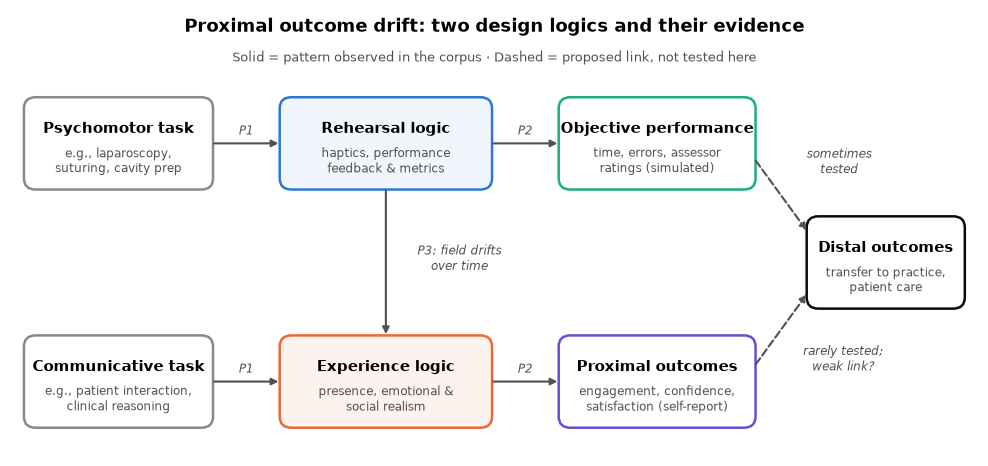

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, title, subtitle, edge, fill="white"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                facecolor=fill, edgecolor=edge, linewidth=1.8))
    ax.text(x + w / 2, y + h * 0.66, title, ha="center", va="center", fontsize=10.5, weight="bold")
    ax.text(x + w / 2, y + h * 0.3, subtitle, ha="center", va="center", fontsize=8.8, color="#52514e")

def arrow(ax, start, end, dashed=False, text=None, tx=0, ty=0, rad=0):
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(
        arrowstyle="-|>", color="#52514e", lw=1.5, linestyle="--" if dashed else "-",
        shrinkA=2, shrinkB=2, connectionstyle=f"arc3,rad={rad}"))
    if text:
        ax.text((start[0] + end[0]) / 2 + tx, (start[1] + end[1]) / 2 + ty, text,
                fontsize=8.8, color="#52514e", ha="center", style="italic")

fig, ax = plt.subplots(figsize=(12.5, 5.8))
ax.set_xlim(0, 12.5)
ax.set_ylim(0.6, 6.6)
ax.axis("off")

# Task types
box(ax, 0.2, 4.2, 2.4, 1.2, "Psychomotor task", "e.g., laparoscopy,\nsuturing, cavity prep", "#8a8984")
box(ax, 0.2, 1.0, 2.4, 1.2, "Communicative task", "e.g., patient interaction,\nclinical reasoning", "#8a8984")

# Design logics
box(ax, 3.5, 4.2, 2.7, 1.2, "Rehearsal logic", "haptics, performance\nfeedback & metrics", "#2a78d6", "#f1f6fd")
box(ax, 3.5, 1.0, 2.7, 1.2, "Experience logic", "presence, emotional &\nsocial realism", "#eb6834", "#fdf3ee")

# Evaluation
box(ax, 7.1, 4.2, 2.5, 1.2, "Objective performance", "time, errors, assessor\nratings (simulated)", "#1baf7a")
box(ax, 7.1, 1.0, 2.5, 1.2, "Proximal outcomes", "engagement, confidence,\nsatisfaction (self-report)", "#6250d6")

# Distal outcomes
box(ax, 10.3, 2.6, 2.0, 1.2, "Distal outcomes", "transfer to practice,\npatient care", "#0b0b0b")

arrow(ax, (2.6, 4.8), (3.5, 4.8), text="P1", ty=0.12)
arrow(ax, (2.6, 1.6), (3.5, 1.6), text="P1", ty=0.12)
arrow(ax, (6.2, 4.8), (7.1, 4.8), text="P2", ty=0.12)
arrow(ax, (6.2, 1.6), (7.1, 1.6), text="P2", ty=0.12)
arrow(ax, (4.85, 4.2), (4.85, 2.2), text="P3: field drifts\nover time", tx=0.95, ty=-0.1)
arrow(ax, (9.6, 4.6), (10.3, 3.6), dashed=True, text="sometimes\ntested", tx=0.75, ty=0.3)
arrow(ax, (9.6, 1.8), (10.3, 2.8), dashed=True, text="rarely tested;\nweak link?", tx=0.8, ty=-0.55)

ax.text(6.25, 6.3, "Proximal outcome drift: two design logics and their evidence", ha="center",
        fontsize=13, weight="bold")
ax.text(6.25, 5.9, "Solid = pattern observed in the corpus · Dashed = proposed link, not tested here",
        ha="center", fontsize=9, color="#52514e")

fig.savefig("fig_theory_model.png", dpi=220, bbox_inches="tight")
plt.show()

In [ ]:
import glob, os, zipfile
import pandas as pd

PUBLIC = Fa   # True = public repository (no abstracts); False = private repository (everything)

skip = {"Untitled1.ipynb", "fig6_theory_model.png"}
files = [f for pattern in ("*.ipynb", "*.csv", "*.xlsx", "*.png") for f in glob.glob(pattern)
         if f not in skip]

def has_abstracts(path):
    """True if a data file contains abstract text columns."""
    try:
        cols = (pd.read_csv(path, nrows=0) if path.endswith(".csv")
                else pd.read_excel(path, nrows=0)).columns
    except Exception:
        return False
    return any(c in cols for c in ("Description", "analysis_text"))

included, left_out = [], []
for f in sorted(files):
    if PUBLIC and f.endswith((".csv", ".xlsx")) and has_abstracts(f):
        left_out.append(f)
    else:
        included.append(f)

with zipfile.ZipFile("github_upload.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in included:
        folder = "figures" if f.endswith(".png") else ("data" if f.endswith((".csv", ".xlsx")) else "")
        z.write(f, os.path.join(folder, f))

print("Put in the zip:", *included, sep="\n  ")
print("\nLeft out (contain abstracts):", *left_out, sep="\n  ")